In [ ]:
import numpy as np
from scipy.optimize import nnls
import time

def proj_cone(G, u):
    """
    Proyecta el vector u sobre el cono convexo P = cone(G)
    mediante mínimos cuadrados no negativos (equivalente a lsqnonneg en MATLAB).
    """
    x, _ = nnls(G, u)
    return G @ x

def excess_projection_spherical_differentiable(G, H, t=0.2, tol=1e-5, max_iter=1000, u0=None):
    """
    Caso Esférico (Optimización Riemanniana sobre la Esfera S^{n-1}).
    
    Parámetros:
        G : array_like (n, p) - Generadores del cono P.
        H : array_like (n, q) - Generadores del cono Q.
        t : float - Tamaño de paso (stepsize).
        tol : float - Tolerancia para la norma de cambio entre iteraciones.
        max_iter : int - Número máximo de iteraciones.
        u0 : array_like (n,), opcional - Punto inicial en el cono P.
        
    Retorna:
        dict : {'val': cos(exceso_esférico), 'u': óptimo, 'iterations': int, 
                'converged': bool, 'time_sec': float}
    """
    n, p = G.shape
    q = H.shape[1]
    
    # Normalizar columnas de las matrices generadoras a norma unitaria
    G = G / np.linalg.norm(G, axis=0, keepdims=True)
    H = H / np.linalg.norm(H, axis=0, keepdims=True)
    
    # Punto inicial
    if u0 is None:
        xr = np.random.rand(p)
        ur = G @ xr
        u0 = ur / np.linalg.norm(ur)
    else:
        u0 = u0 / np.linalg.norm(u0)
        
    u = u0.copy()
    I = np.eye(n)
    
    start_time = time.perf_counter()
    converged = False
    g = np.zeros(n)
    
    for i in range(1, max_iter + 1):
        projuQ = proj_cone(H, u)
        norm_projuQ = np.linalg.norm(projuQ)
        
        if norm_projuQ < 1e-12:
            g = np.zeros(n)
        else:
            g = projuQ / norm_projuQ
            
        # Gradiente en el espacio tangente a la esfera S^{n-1}
        grad = (I - np.outer(u, u)) @ g
        ngrad = np.linalg.norm(grad)
        
        # Descenso a lo largo de la geodésica esférica

        us = np.cos(t * ngrad) * u - np.sin(t * ngrad) * (grad / ngrad)
            
        # Proyección Euclidiana sobre P y normalización a la esfera
        projuP = proj_cone(G, us)
        norm_projuP = np.linalg.norm(projuP)
        
        if norm_projuP < 1e-12:
            u_update = u.copy()
        else:
            u_update = projuP / norm_projuP
            
        if np.linalg.norm(u_update - u) < tol:
            converged = True
            break
            
        u = u_update
        
    elapsed_time = time.perf_counter() - start_time
    val = np.dot(u, g) if norm_projuQ >= 1e-12 else 0.0
    
    return {
        'val': float(val),
        'u': u,
        'iterations': i,
        'converged': converged,
        'time_sec': elapsed_time
    }


def excess_projection_euclidean_differentiable(G, H, t=0.2, tol=1e-5, max_iter=1000, u0=None):
    """
    Caso Euclídeo (Gradiente Proyectado Tradicional en R^n con Retracción a S^{n-1}).
    """
    n, p = G.shape
    q = H.shape[1]
    
    G = G / np.linalg.norm(G, axis=0, keepdims=True)
    H = H / np.linalg.norm(H, axis=0, keepdims=True)
    
    if u0 is None:
        xr = np.random.rand(p)
        ur = G @ xr
        u0 = ur / np.linalg.norm(ur)
    else:
        u0 = u0 / np.linalg.norm(u0)
        
    u = u0.copy()
    start_time = time.perf_counter()
    converged = False
    g = np.zeros(n)
    
    for i in range(1, max_iter + 1):
        projuQ = proj_cone(H, u)
        norm_projuQ = np.linalg.norm(projuQ)
        
        if norm_projuQ < 1e-12:
            g = np.zeros(n)
        else:
            g = projuQ / norm_projuQ
            
        # Paso euclídeo directo en R^n
        us = u - t * g
        
        # Proyección sobre el cono P y retracción (normalización)
        projuP = proj_cone(G, us)
        norm_projuP = np.linalg.norm(projuP)
        
        if norm_projuP < 1e-12:
            u_update = u.copy()
        else:
            u_update = projuP / norm_projuP
            
        if np.linalg.norm(u_update - u) < tol:
            converged = True
            break
            
        u = u_update
        
    elapsed_time = time.perf_counter() - start_time
    val = np.dot(u, g) if norm_projuQ >= 1e-12 else 0.0
    
    return {
        'val': float(val),
        'u': u,
        'iterations': i,
        'converged': converged,
        'time_sec': elapsed_time
    }

In [2]:
if __name__ == "__main__":
    # Matrices de generadores en el ortante positivo (R^4_+)
    G = np.array([
        [1.0, 0.0, 0.2],
        [0.8, 1.0, 0.0],
        [0.0, 0.5, 0.9],
        [0.1, 0.1, 1.0]
    ])
    
    H = np.array([
        [0.1, 0.9, 0.0],
        [0.0, 0.2, 0.8],
        [1.0, 0.0, 0.5],
        [0.5, 0.3, 0.0]
    ])

    # Fijar semilla para reproducibilidad del punto inicial
    np.random.seed(42)
    p = G.shape[1]
    xr = np.random.rand(p)
    u0 = G @ xr
    u0 /= np.linalg.norm(u0)

    # Ejecución de ambos enfoques
    res_sph = excess_projection_spherical_differentiable(G, H, t=0.2, tol=1e-5, max_iter=1000, u0=u0)
    res_euc = excess_projection_euclidean_differentiable(G, H, t=0.2, tol=1e-5, max_iter=1000, u0=u0)

    print("--- RESULTADOS MÉTODO ESFÉRICO ---")
    print(f"Coseno del exceso esférico: {res_sph['val']:.6f}")
    print(f"Ángulo equivalente (grados): {np.degrees(np.arccos(np.clip(res_sph['val'], -1.0, 1.0))):.2f}°")
    print(f"Vector óptimo u*: {np.round(res_sph['u'], 4)}")
    print(f"Iteraciones requeridas: {res_sph['iterations']}")
    print(f"¿Convergió?: {res_sph['converged']}")
    print(f"Tiempo de cómputo: {res_sph['time_sec']*1000:.2f} ms\n")

    print("--- RESULTADOS MÉTODO EUCLÍDEO ---")
    print(f"Coseno del exceso esférico: {res_euc['val']:.6f}")
    print(f"Ángulo equivalente (grados): {np.degrees(np.arccos(np.clip(res_euc['val'], -1.0, 1.0))):.2f}°")
    print(f"Vector óptimo u*: {np.round(res_euc['u'], 4)}")
    print(f"Iteraciones requeridas: {res_euc['iterations']}")
    print(f"¿Convergió?: {res_euc['converged']}")
    print(f"Tiempo de cómputo: {res_euc['time_sec']*1000:.2f} ms")

--- RESULTADOS MÉTODO ESFÉRICO ---
Coseno del exceso esférico: 0.944231
Ángulo equivalente (grados): 19.23°
Vector óptimo u*: [0.147  0.     0.6617 0.7352]
Iteraciones requeridas: 124
¿Convergió?: True
Tiempo de cómputo: 39.13 ms

--- RESULTADOS MÉTODO EUCLÍDEO ---
Coseno del exceso esférico: 0.944231
Ángulo equivalente (grados): 19.23°
Vector óptimo u*: [0.147  0.     0.6617 0.7352]
Iteraciones requeridas: 101
¿Convergió?: True
Tiempo de cómputo: 14.00 ms


In [28]:
def matriz_schur_identidad(n):

  ident = np.eye(n)

  schur = ident[:,0] - ident[:,1]

  for i in range(1,n-1):

    schur = np.vstack((schur, ident[:,i] - ident[:,i+1]))

  schur = schur.T

  return schur/np.linalg.norm(schur, axis = 0 , keepdims=True), np.eye(n)

In [ ]:
if __name__ == "__main__":
    # Matrices de generadores en el ortante positivo (R^4_+)
    S,I = matriz_schur_identidad(50)
    G = S
    H = I
    # Fijar semilla para reproducibilidad del punto inicial
    np.random.seed(42)
    p = G.shape[1]
    xr = np.random.rand(p)
    u0 = G @ xr
    u0 /= np.linalg.norm(u0)

    # Ejecución de ambos enfoques
    res_sph = excess_projection_spherical_differentiable(G, H, t=0.2, tol=1e-5, max_iter=1000, u0=u0)
    res_euc = excess_projection_euclidean_differentiable(G, H, t=0.2, tol=1e-5, max_iter=1000, u0=u0)

    print("--- RESULTADOS MÉTODO ESFÉRICO ---")
    print(f"Coseno del exceso esférico: {res_sph['val']:.6f}")
    print(f"Ángulo equivalente (grados): {np.degrees(np.arccos(np.clip(res_sph['val'], -1.0, 1.0))):.2f}°")
    print(f"Vector óptimo u*: {np.round(res_sph['u'], 4)}")
    print(f"Iteraciones requeridas: {res_sph['iterations']}")
    print(f"Convergencia: {res_sph['converged']}")
    print(f"Tiempo de cómputo: {res_sph['time_sec']*1000:.2f} ms\n")

    print("--- RESULTADOS MÉTODO EUCLÍDEO ---")
    print(f"Coseno del exceso esférico: {res_euc['val']:.6f}")
    print(f"Ángulo equivalente (grados): {np.degrees(np.arccos(np.clip(res_euc['val'], -1.0, 1.0))):.2f}°")
    print(f"Vector óptimo u*: {np.round(res_euc['u'], 4)}")
    print(f"Iteraciones requeridas: {res_euc['iterations']}")
    print(f"Convergencia: {res_euc['converged']}")
    print(f"Tiempo de cómputo: {res_euc['time_sec']*1000:.2f} ms")
    # hacer experimento n = 5 y 10 generadores. 
    # ver dos conos en los que el angulo máximo no sea pi

--- RESULTADOS MÉTODO ESFÉRICO ---
Coseno del exceso esférico: 0.149071
Ángulo equivalente (grados): 81.43°
Vector óptimo u*: [ 0.0225  0.0225  0.0225  0.0225  0.0225  0.0225  0.0225  0.0225  0.0225
  0.0225  0.0225  0.0225  0.0225  0.0225  0.0225  0.0225  0.0225  0.0225
  0.0225  0.0225  0.0225  0.0225  0.0225  0.0225  0.0225  0.0225  0.0225
  0.0225  0.0225  0.0225  0.0225  0.0225  0.0225  0.0225  0.0225  0.0225
  0.0225  0.0225  0.0225  0.0225  0.0225  0.0225  0.0225  0.0225 -0.9888
  0.      0.      0.      0.     -0.    ]
Iteraciones requeridas: 77
Convergencia: True
Tiempo de cómputo: 87.45 ms

--- RESULTADOS MÉTODO EUCLÍDEO ---
Coseno del exceso esférico: 0.149071
Ángulo equivalente (grados): 81.43°
Vector óptimo u*: [ 0.0225  0.0225  0.0225  0.0225  0.0225  0.0225  0.0225  0.0225  0.0225
  0.0225  0.0225  0.0225  0.0225  0.0225  0.0225  0.0225  0.0225  0.0225
  0.0225  0.0225  0.0225  0.0225  0.0225  0.0225  0.0225  0.0225  0.0225
  0.0225  0.0225  0.0225  0.0225  0.0225  0.022

In [ ]:
np.eye(3)[:, :2]

array([0., 0., 1.])

In [ ]:
H = np.eye(3)[:, :2]
G = [np.eye(3)[0] + np.eye(3)[2] , np.eye(3)[1] + np.eye(3)[2]]

In [21]:
np.array([np.eye(3)[0] + np.eye(3)[2] , np.eye(3)[1] + np.eye(3)[2]]).T

array([[1., 0.],
       [0., 1.],
       [1., 1.]])

In [26]:
if __name__ == "__main__":
    # Matrices de generadores en el ortante positivo (R^4_+)
    H = np.eye(3)[:, :2]
    G = np.array([np.eye(3)[0] + np.eye(3)[2] , np.eye(3)[1] + np.eye(3)[2]]).T
    # Fijar semilla para reproducibilidad del punto inicial
    np.random.seed(42)
    p = G.shape[1]
    xr = np.random.rand(p)
    u0 = G @ xr
    u0 /= np.linalg.norm(u0)

    # Ejecución de ambos enfoques
    res_sph = excess_projection_spherical_differentiable(G, H, t=0.2, tol=1e-5, max_iter=1000, u0=u0)
    res_euc = excess_projection_euclidean_differentiable(G, H, t=0.2, tol=1e-5, max_iter=1000, u0=u0)

    print("ESFÉRICO")
    print("="*30)
    print(f"Coseno: {res_sph['val']:.6f}")
    print(f"Ángulo (grados): {np.degrees(np.arccos(np.clip(res_sph['val'], -1.0, 1.0))):.2f}°")
    print(f"Vector óptimo u*: {np.round(res_sph['u'], 4)}")
    print(f"Iteraciones: {res_sph['iterations']}")
    print(f"Convergencia: {res_sph['converged']}")
    print(f"Tiempo de cómputo: {res_sph['time_sec']*1000:.2f} ms\n")

    print("EUCLÍDEO")
    print("="*30)
    print(f"Coseno: {res_euc['val']:.6f}")
    print(f"Ángulo (grados): {np.degrees(np.arccos(np.clip(res_euc['val'], -1.0, 1.0))):.2f}°")
    print(f"Vector óptimo u*: {np.round(res_euc['u'], 4)}")
    print(f"Iteraciones: {res_euc['iterations']}")
    print(f"Convergencia: {res_euc['converged']}")
    print(f"Tiempo de cómputo: {res_euc['time_sec']*1000:.2f} ms")

ESFÉRICO
Coseno: 0.577350
Ángulo (grados): 54.74°
Vector óptimo u*: [0.4082 0.4083 0.8165]
Iteraciones: 34
Convergencia: True
Tiempo de cómputo: 7.58 ms

EUCLÍDEO
Coseno: 0.577350
Ángulo (grados): 54.74°
Vector óptimo u*: [0.4082 0.4083 0.8165]
Iteraciones: 31
Convergencia: True
Tiempo de cómputo: 3.31 ms


# hacer experimento n = 5 y 10 generadores. 
# ver dos conos en los que el angulo máximo no sea pi

In [32]:
# n = 5 y 10 generadores 
A = np.array([
    [2.1, 8.2, 3.1, 7.0, 4.2],
    [1.8, 7.5, 2.7, 6.8, 3.9],
    [2.5, 8.7, 3.4, 7.6, 4.5],
    [2.2, 7.9, 3.6, 6.5, 4.1],
    [1.7, 8.4, 2.9, 7.3, 3.7],
    [2.8, 7.7, 3.2, 6.9, 4.6],
    [2.0, 8.9, 3.7, 7.8, 4.0],
    [2.4, 8.1, 2.8, 6.7, 4.4],
    [1.9, 7.8, 3.3, 7.5, 3.8],
    [2.6, 8.5, 3.0, 7.1, 4.3]
]).T

B = np.array([
    [8.1, 2.1, 7.2, 3.0, 8.3],
    [7.6, 1.8, 6.8, 3.4, 7.9],
    [8.7, 2.5, 7.5, 2.7, 8.8],
    [8.2, 2.2, 6.9, 3.6, 8.1],
    [7.9, 1.7, 7.8, 3.1, 8.5],
    [8.5, 2.8, 7.1, 2.9, 7.7],
    [7.7, 2.0, 7.4, 3.7, 8.9],
    [8.9, 2.4, 6.7, 3.2, 8.2],
    [8.3, 1.9, 7.7, 2.8, 7.8],
    [7.8, 2.6, 7.0, 3.5, 8.6]
]).T



In [ ]:

# Matrices de generadores en el ortante positivo (R^4_+)
H = A
G = B
# Fijar semilla para reproducibilidad del punto inicial
np.random.seed(42)
p = G.shape[1]
xr = np.random.rand(p)
u0 = G @ xr
u0 /= np.linalg.norm(u0)

print("G\n", G)
print('-'*30)
print("H\n", H)

# Ejecución de ambos enfoques
res_sph = excess_projection_spherical_differentiable(G, H, t=0.2, tol=1e-5, max_iter=1000, u0=u0)
res_euc = excess_projection_euclidean_differentiable(G, H, t=0.2, tol=1e-5, max_iter=1000, u0=u0)

print("ESFÉRICO")
print("="*30)
print(f"Coseno: {res_sph['val']:.6f}")
print(f"Ángulo (grados): {np.degrees(np.arccos(np.clip(res_sph['val'], -1.0, 1.0))):.2f}°")
print(f"Vector óptimo u*: {np.round(res_sph['u'], 4)}")
print(f"Iteraciones: {res_sph['iterations']}")
print(f"Convergencia: {res_sph['converged']}")
print(f"Tiempo de cómputo: {res_sph['time_sec']*1000:.2f} ms\n")

print("EUCLÍDEO")
print("="*30)
print(f"Coseno: {res_euc['val']:.6f}")
print(f"Ángulo (grados): {np.degrees(np.arccos(np.clip(res_euc['val'], -1.0, 1.0))):.2f}°")
print(f"Vector óptimo u*: {np.round(res_euc['u'], 4)}")
print(f"Iteraciones: {res_euc['iterations']}")
print(f"Convergencia: {res_euc['converged']}")
print(f"Tiempo de cómputo: {res_euc['time_sec']*1000:.2f} ms")

In [35]:
A = np.array([
    [ 4.0,  2.0,  1.0, -3.0,  5.0],
    [ 5.0,  1.0,  2.0, -2.5,  4.5],
    [ 3.5,  2.5,  0.5, -3.5,  5.5],
    [ 4.5,  1.5,  1.5, -2.0,  5.0],
    [ 3.8,  2.2,  1.2, -3.2,  5.2],
    [ 4.2,  1.8,  0.8, -2.8,  5.4],
    [ 3.7,  2.3,  1.4, -3.0,  5.1],
    [ 4.4,  1.6,  1.0, -2.4,  5.3],
    [ 3.9,  2.1,  0.7, -3.3,  5.6],
    [ 4.1,  1.9,  1.3, -2.6,  5.0]
]).T

B = np.array([
    [-3.0,  5.0,  4.0,  2.0,  1.0],
    [-2.5,  4.5,  5.0,  1.5,  2.0],
    [-3.5,  5.5,  3.5,  2.5,  0.5],
    [-2.0,  5.0,  4.5,  1.0,  1.5],
    [-3.2,  5.2,  3.8,  2.2,  1.2],
    [-2.8,  5.4,  4.2,  1.8,  0.8],
    [-3.0,  5.1,  3.7,  2.3,  1.4],
    [-2.4,  5.3,  4.4,  1.6,  1.0],
    [-3.3,  5.6,  3.9,  2.1,  0.7],
    [-2.6,  5.0,  4.1,  1.9,  1.3]
]).T

# n = 5 y 10 generadores 



# Matrices de generadores en el ortante positivo (R^4_+)
H = A
G = B
# Fijar semilla para reproducibilidad del punto inicial
np.random.seed(42)
p = G.shape[1]
xr = np.random.rand(p)
u0 = G @ xr
u0 /= np.linalg.norm(u0)

print("G\n", G)
print('-'*30)
print("H\n", H)

# Ejecución de ambos enfoques
res_sph = excess_projection_spherical_differentiable(G, H, t=0.2, tol=1e-5, max_iter=1000, u0=u0)
res_euc = excess_projection_euclidean_differentiable(G, H, t=0.2, tol=1e-5, max_iter=1000, u0=u0)

print("ESFÉRICO")
print("="*30)
print(f"Coseno: {res_sph['val']:.6f}")
print(f"Ángulo (grados): {np.degrees(np.arccos(np.clip(res_sph['val'], -1.0, 1.0))):.2f}°")
print(f"Vector óptimo u*: {np.round(res_sph['u'], 4)}")
print(f"Iteraciones: {res_sph['iterations']}")
print(f"Convergencia: {res_sph['converged']}")
print(f"Tiempo de cómputo: {res_sph['time_sec']*1000:.2f} ms\n")

print("EUCLÍDEO")
print("="*30)
print(f"Coseno: {res_euc['val']:.6f}")
print(f"Ángulo (grados): {np.degrees(np.arccos(np.clip(res_euc['val'], -1.0, 1.0))):.2f}°")
print(f"Vector óptimo u*: {np.round(res_euc['u'], 4)}")
print(f"Iteraciones: {res_euc['iterations']}")
print(f"Convergencia: {res_euc['converged']}")
print(f"Tiempo de cómputo: {res_euc['time_sec']*1000:.2f} ms")

G
 [[-3.  -2.5 -3.5 -2.  -3.2 -2.8 -3.  -2.4 -3.3 -2.6]
 [ 5.   4.5  5.5  5.   5.2  5.4  5.1  5.3  5.6  5. ]
 [ 4.   5.   3.5  4.5  3.8  4.2  3.7  4.4  3.9  4.1]
 [ 2.   1.5  2.5  1.   2.2  1.8  2.3  1.6  2.1  1.9]
 [ 1.   2.   0.5  1.5  1.2  0.8  1.4  1.   0.7  1.3]]
------------------------------
H
 [[ 4.   5.   3.5  4.5  3.8  4.2  3.7  4.4  3.9  4.1]
 [ 2.   1.   2.5  1.5  2.2  1.8  2.3  1.6  2.1  1.9]
 [ 1.   2.   0.5  1.5  1.2  0.8  1.4  1.   0.7  1.3]
 [-3.  -2.5 -3.5 -2.  -3.2 -2.8 -3.  -2.4 -3.3 -2.6]
 [ 5.   4.5  5.5  5.   5.2  5.4  5.1  5.3  5.6  5. ]]
ESFÉRICO
Coseno: 0.000000
Ángulo (grados): 90.00°
Vector óptimo u*: [-0.4472  0.7028  0.4472  0.3194  0.0639]
Iteraciones: 3
Convergencia: True
Tiempo de cómputo: 7.93 ms

EUCLÍDEO
Coseno: 0.000000
Ángulo (grados): 90.00°
Vector óptimo u*: [-0.4472  0.7028  0.4472  0.3194  0.0639]
Iteraciones: 3
Convergencia: True
Tiempo de cómputo: 0.47 ms


# complemento para el caso en el que $u \in Q^{\circ}$

El problema es 
$$\min t\\
s.t.\\
 (t,x) \in \mathbb{R} \times \mathbb{R}^{n}\\
 G^THx - \mathcal{1}_nt \le 0\\
 - x \le 0\\
 \|Hx\|- 1 \le 0 
 $$

In [1]:
# problema 
from scipy.optimize import minimize
def problema_polar(G,H):
    # G,H son matrices de generadores de los conos P y Q respectivamente.
    n = G.shape[0]
    iterados = []
    def callback(z):
        iterados.append(z.copy())
    def constraint_GH(z , G, H):
        # desigualdad
        t = z[0]
        x = z[1:]
        return -((H.T@G)@x - t)
    def constraint_x(z):
        # desigualdad
        x = z[1:]
        return x
    def constraint_norm(z,G):
        # desgualdad
        return -(np.linalg.norm(G@z[1:])**2 - 1)

    def f_objetivo(z):
        return z[0]  # minimizar t
    z0 = np.ones(n+1)  # punto inicial (t, x)

    restricciones = [
        {'type': 'ineq', 'fun': constraint_GH, 'args':(G,H)},
        {'type': 'ineq', 'fun': constraint_x},
        {'type': 'ineq', 'fun': constraint_norm, 'args':(G,)},
    ]
    result = minimize(f_objetivo, z0, method='SLSQP', constraints=restricciones, callback=callback)
    t_opt = result.x[0]
    x_opt = result.x[1:]
    distancias = [
        np.linalg.norm(iterados[k+1] - iterados[k])
        for k in range(len(iterados)-1)
    ]
    return t_opt, x_opt, distancias

In [118]:
help(minimize)

Help on function minimize in module scipy.optimize._minimize:

minimize(fun, x0, args=(), method=None, jac=None, hess=None, hessp=None, bounds=None, constraints=(), tol=None, callback=None, options=None)
    Minimization of scalar function of one or more variables.
    
    Parameters
    ----------
    fun : callable
        The objective function to be minimized::
    
            fun(x, *args) -> float
    
        where ``x`` is a 1-D array with shape (n,) and ``args``
        is a tuple of the fixed parameters needed to completely
        specify the function.
    
        Suppose the callable has signature ``f0(x, *my_args, **my_kwargs)``, where
        ``my_args`` and ``my_kwargs`` are required positional and keyword arguments.
        Rather than passing ``f0`` as the callable, wrap it to accept
        only ``x``; e.g., pass ``fun=lambda x: f0(x, *my_args, **my_kwargs)`` as the
        callable, where ``my_args`` (tuple) and ``my_kwargs`` (dict) have been
        gathered befo

In [16]:
import numpy as np
import time
from scipy.optimize import minimize, nnls
def problema_polar(G,H):
    # G,H son matrices de generadores de los conos P y Q respectivamente.
    n = G.shape[0]
    iterados = []
    def callback(z):
        iterados.append(z.copy())
    def constraint_GH(z , G, H):
        # desigualdad
        t = z[0]
        x = z[1:]
        return -((H.T@G)@x - t)
    def constraint_x(z):
        # desigualdad
        x = z[1:]
        return x
    def constraint_norm(z,G):
        # desgualdad
        return -(np.linalg.norm(G@z[1:])**2 - 1)

    def f_objetivo(z):
        return z[0]  # minimizar t
    z0 = np.ones(n+1)  # punto inicial (t, x)

    restricciones = [
        {'type': 'ineq', 'fun': constraint_GH, 'args':(G,H)},
        {'type': 'ineq', 'fun': constraint_x},
        {'type': 'ineq', 'fun': constraint_norm, 'args':(G,)},
    ]
    result = minimize(f_objetivo, z0, method='SLSQP', constraints=restricciones, callback=callback)
    t_opt = result.x[0]
    x_opt = result.x[1:]
    distancias = [
        np.linalg.norm(iterados[k+1] - iterados[k])
        for k in range(len(iterados)-1)
    ]
    return t_opt, x_opt, distancias

def proj_cone(G, u):
    """
    Proyecta el vector u sobre el cono convexo P = cone(G)
    mediante mínimos cuadrados no negativos (equivalente a lsqnonneg en MATLAB).
    """
    x, _ = nnls(G, u)
    return G @ x
def es_polar(u,H, tol = 1e-8):
    return np.all(H.T @ u <= tol)
def f_obj(u):
    return np.linalg.norm(proj_cone(H, u))
def gradiente(u):
    projuQ = proj_cone(H, u)
    norma_projuQ = np.linalg.norm(projuQ)
    if norma_projuQ < 1e-12:
        return np.zeros_like(u)
    else:
        return projuQ / norma_projuQ
def linesearch(u, g, t0=1.0, alpha=0.5, beta=0.5):
    t = t0
    while f_obj(u - t * g) > f_obj(u) - alpha * t * np.dot(g, g):
        t *= beta
    return t
def exceso_gradiente_proyectado_optimizado(G, H, t = 0.1, max_iter=1000, eps=1e-5):
    G = G / np.linalg.norm(G, axis=0, keepdims=True)
    H = H / np.linalg.norm(H, axis=0, keepdims=True)
    n = G.shape[0]
    p = G.shape[1]
    q = H.shape[1]
    u0 = G@np.ones(p)
    u0 = u0 / np.linalg.norm(u0)
    u_curr = u0.copy()
    valores_normas = []
    # bucle 
    converged = False
    tiempo = time.perf_counter()
    t_act = t
    for k in range(1, max_iter + 1):
        # verificar si es polar o no 
        if es_polar(u_curr,H):
            t_opt, u_opt, distancias = problema_polar(G,H)
            valores_normas += distancias
            converged = True
            break
            
        # de no ser polar, inicia el descenso proyectado
        projuQ = proj_cone(H, u_curr)
        norma_projuQ = np.linalg.norm(projuQ)
        # gradiente
        if norma_projuQ < 1e-12:
            g = np.zeros(n)
        else:
            g = gradiente(u_curr)
        # Paso euclídeo directo en R^n
        t_k = max(t_act , 1e-6)  # Evitar pasos demasiado pequeños
        t_act = linesearch(u_curr, g, t0 = t_k)
        us = u_curr - t_act * g
        # Proyección sobre el cono P y retracción (normalización)
        projuP = proj_cone(G, us)
        norm_projuP = np.linalg.norm(projuP)
        
        if norm_projuP < 1e-12:
            u_update = u_curr.copy()
        else:
            u_update = projuP / norm_projuP
            
        if np.linalg.norm(u_update - u_curr) < eps:
            converged = True
            u_opt = u_update
            break
        valores_normas.append(np.linalg.norm(u_update - u_curr))
        u_curr = u_update
    v_opt = proj_cone(H, u_curr)/np.linalg.norm(proj_cone(H, u_curr))
    tiempo_final = time.perf_counter() - tiempo
    resultados = {"u_opt": u_opt, "v_opt": v_opt,"coseno" :np.dot(v_opt, u_opt) , 
            "angulo": np.arccos(np.clip(np.dot(v_opt, u_opt), -1, 1)), 
            "tiempo_final": tiempo_final, "k": k, "converged": converged,
              "valores_normas": valores_normas}
    return resultados

In [18]:
# Schur vs I
G, H  = matriz_schur_identidad(10) # P es schur y Q es identidad
resultados_PQ = exceso_gradiente_proyectado_optimizado(G, H, t = .3, max_iter=1000, eps=1e-4)
print(resultados_PQ["coseno"], resultados_PQ["angulo"], resultados_PQ["tiempo_final"], resultados_PQ["k"], resultados_PQ["converged"])

0.31622776562286126 1.2490457728135422 0.002533600003516767 7 True


Text(0, 0.5, '$\\|u_{k+1} - u_k\\|$')

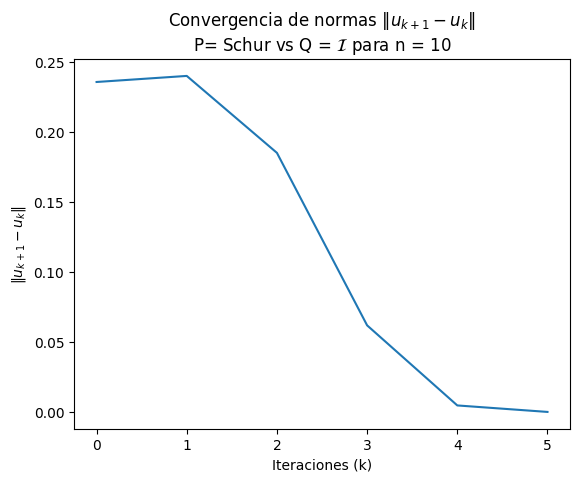

In [114]:
import matplotlib.pyplot as plt

plt.plot(resultados_PQ["valores_normas"])
plt.title(fr"Convergencia de normas $\|u_{{k+1}} - u_k\|$" + "\nP= Schur vs Q = $\mathcal{I}$ para n = 10")
plt.xlabel("Iteraciones (k)")
plt.ylabel(r"$\|u_{k+1} - u_k\|$")

In [115]:
resultados_PQ['tiempo_final']

0.003882199991494417

In [116]:
resultados_QP = exceso_gradiente_proyectado_optimizado(H, G, t = 0.1, max_iter=1000, eps=1e-5)

Text(0, 0.5, '$\\|u_{k+1} - u_k\\|$')

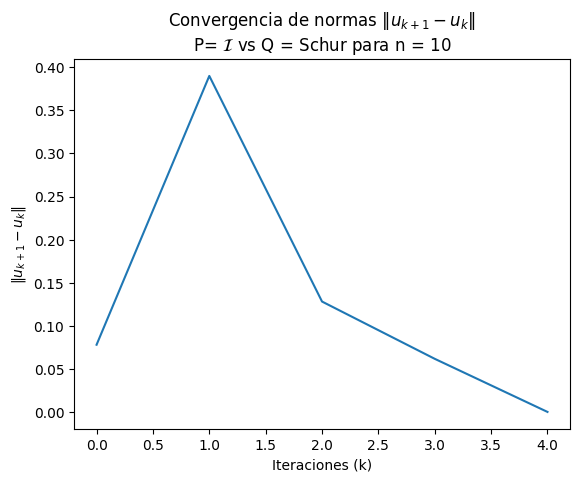

In [117]:
plt.plot(resultados_QP["valores_normas"])
plt.title(fr"Convergencia de normas $\|u_{{k+1}} - u_k\|$" + "\nP= $\mathcal{I}$ vs Q = Schur para n = 10")
plt.xlabel("Iteraciones (k)")
plt.ylabel(r"$\|u_{k+1} - u_k\|$")

=== CASO 1: Cono de Schur Estándar vs Cono Identidad ===
Polo SVM e*: [0.57735027 0.57735027 0.57735027]
u* Re-proyectado: [0.70710678 0.70710678 0.        ]
v* Re-proyectado: [0.70710678 0.70710678 0.        ]
Distancia Esférica: 0.000000
(Nota: El cono de Schur está contenido en el cono Identidad, por lo que la distancia es 0).

=== CASO 2: Conos Disjuntos en el Mismo Hemisferio (S^2) ===
Polo Admisible e*:  [0.64978313 0.46856528 0.5985219 ]
u_hat* en H(e,1):    [1.29956626 0.         0.25991325]
v_hat* en H(e,1):    [0.43189227 0.43189227 0.86378454]
Distancia en H(e,1): 1.141950
--------------------------------------------------
u* Re-proyectado a S^2: [0.98058068 0.         0.19611614]
v* Re-proyectado a S^2: [0.40824829 0.40824829 0.81649658]
Distancia Esférica (Gnomónica): 0.93760489
Distancia Esférica (Directa):   0.93760489
Diferencia / Error Absoluto:    1.11e-16


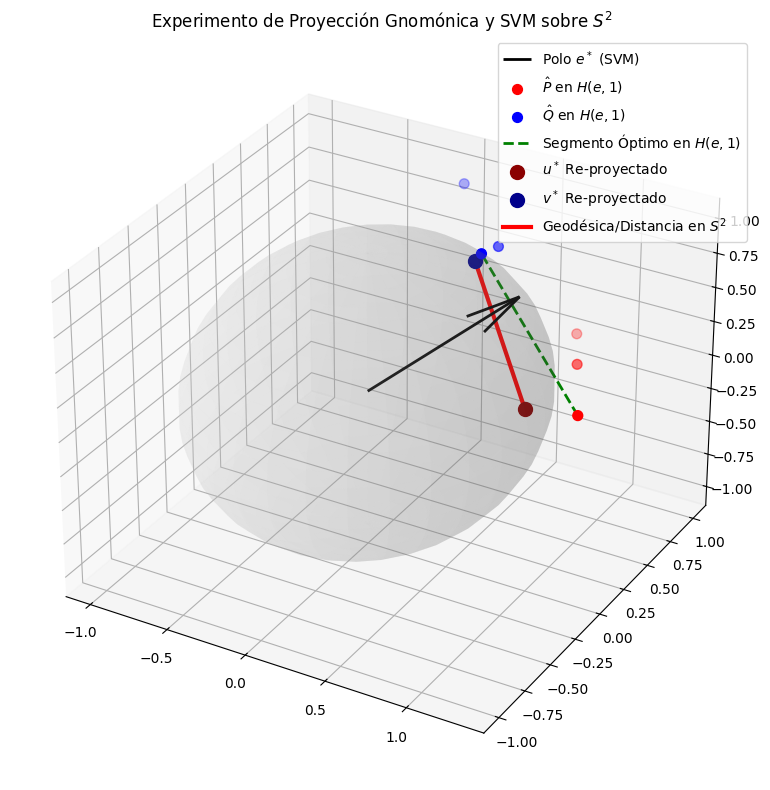

In [20]:
import numpy as np
import scipy.optimize as opt
import matplotlib.pyplot as plt

class GnomonicMaxMinExperiment:
    """
    Experimento para resolver max min ||u - v|| en S^n vía proyección gnomónica
    en el hiperplano tangente H(e,1) derivado por SVM sin sesgo.
    """
    def __init__(self, d=3, P_generators=None, Q_generators=None):
        self.d = d
        
        # 1. Definición de Generadores
        if P_generators is not None:
            self.P_raw = np.array(P_generators, dtype=float)
        else:
            # Cono de Schur estándar (matriz triangular inferior)
            self.P_raw = np.tril(np.ones((d, d)))
            
        if Q_generators is not None:
            self.Q_raw = np.array(Q_generators, dtype=float)
        else:
            # Cono Identidad estándar (base canónica I_d)
            self.Q_raw = np.eye(d)
            
        # Normalización sobre la esfera unitaria S^{d-1}
        self.P_gen = self.P_raw / np.linalg.norm(self.P_raw, axis=1, keepdims=True)
        self.Q_gen = self.Q_raw / np.linalg.norm(self.Q_raw, axis=1, keepdims=True)
        
        self.num_p = self.P_gen.shape[0]
        self.num_q = self.Q_gen.shape[0]
        
        # Variables de estado
        self.w_star = None
        self.e_star = None
        self.P_hat = None
        self.Q_hat = None
        self.u_hat_star = None
        self.v_hat_star = None
        self.u_star = None
        self.v_star = None
        self.gnomonic_dist = None
        self.spherical_dist = None

    def find_admissible_pole_svm(self):
        """
        Calcula el polo óptimo e* resolviendo el problema dual/primal de SVM
        de margen máximo sin término de sesgo (bias=0).
        """
        X = np.vstack([self.P_gen, self.Q_gen])
        
        def objective(w):
            return 0.5 * np.dot(w, w)
        
        def grad_obj(w):
            return w
        
        constraints = {
            'type': 'ineq',
            'fun': lambda w: X @ w - 1.0,
            'jac': lambda w: X
        }
        
        w0 = np.ones(self.d)
        res = opt.minimize(objective, w0, jac=grad_obj, constraints=constraints, method='SLSQP')
        
        if not res.success:
            raise RuntimeError(f"Falló la optimización SVM: {res.message}")
            
        self.w_star = res.x
        self.e_star = self.w_star / np.linalg.norm(self.w_star)
        
        # Verificación de admisibilidad estricta: <x_i, e*> > 0
        margins = X @ self.e_star
        if np.any(margins <= 0):
            raise ValueError("El polo e* no es estrictamente admisible para todos los generadores.")
            
        return self.e_star, margins

    def project_gnomonic(self):
        """
        Proyecta los generadores sobre el hiperplano H(e,1) = {x : <x, e*> = 1}
        g_e(u) = u / <u, e*>
        """
        if self.e_star is None:
            self.find_admissible_pole_svm()
            
        self.P_hat = self.P_gen / (self.P_gen @ self.e_star)[:, None]
        self.Q_hat = self.Q_gen / (self.Q_gen @ self.e_star)[:, None]
        return self.P_hat, self.Q_hat

    def _min_dist_to_Q_hat(self, u_hat):
        """
        Dado u_hat en H(e,1), resuelve el problema convexo interno:
        min_{beta >= 0, sum(beta)=1} || u_hat - sum(beta_j * h_j_hat) ||_2
        """
        def obj(beta):
            v_hat = self.Q_hat.T @ beta
            return np.linalg.norm(u_hat - v_hat)
        
        beta0 = np.ones(self.num_q) / self.num_q
        bounds = [(0, 1)] * self.num_q
        constraints = {'type': 'eq', 'fun': lambda beta: np.sum(beta) - 1.0}
        
        res = opt.minimize(obj, beta0, bounds=bounds, constraints=constraints, method='SLSQP')
        v_hat_opt = self.Q_hat.T @ res.x
        return res.fun, v_hat_opt

    def solve_max_min_gnomonic(self):
        """
        Resuelve el problema max_{u_hat in conv(P_hat)} min_{v_hat in conv(Q_hat)} ||u_hat - v_hat||
        Evaluación sobre los puntos extremales de P_hat.
        """
        if self.P_hat is None:
            self.project_gnomonic()
            
        best_dist = -1.0
        best_u_hat = None
        best_v_hat = None
        
        for i in range(self.num_p):
            u_cand = self.P_hat[i]
            dist_val, v_cand = self._min_dist_to_Q_hat(u_cand)
            if dist_val > best_dist:
                best_dist = dist_val
                best_u_hat = u_cand
                best_v_hat = v_cand
                
        self.gnomonic_dist = best_dist
        self.u_hat_star = best_u_hat
        self.v_hat_star = best_v_hat
        return best_dist, best_u_hat, best_v_hat

    def reproject_to_sphere(self):
        """
        Re-proyección inversa de los óptimos en H(e,1) hacia la esfera S^{d-1}:
        u* = u_hat* / ||u_hat*||_2,  v* = v_hat* / ||v_hat*||_2
        """
        if self.u_hat_star is None:
            self.solve_max_min_gnomonic()
            
        self.u_star = self.u_hat_star / np.linalg.norm(self.u_hat_star)
        self.v_star = self.v_hat_star / np.linalg.norm(self.v_hat_star)
        self.spherical_dist = np.linalg.norm(self.u_star - self.v_star)
        
        return self.u_star, self.v_star, self.spherical_dist

    def validate_direct_spherical(self):
        """
        Calcula la solución directa sobre S^{d-1} para validar exactitud.
        """
        def sphere_min_dist_to_Q(u_sph):
            def obj(lam):
                v_unnorm = self.Q_gen.T @ lam
                v_sph = v_unnorm / np.linalg.norm(v_unnorm)
                return np.linalg.norm(u_sph - v_sph)
            
            lam0 = np.ones(self.num_q) / self.num_q
            bounds = [(0, None)] * self.num_q
            constraints = {'type': 'ineq', 'fun': lambda lam: np.sum(lam) - 1e-5}
            res = opt.minimize(obj, lam0, bounds=bounds, constraints=constraints, method='SLSQP')
            v_opt_unnorm = self.Q_gen.T @ res.x
            v_opt_sph = v_opt_unnorm / np.linalg.norm(v_opt_unnorm)
            return res.fun, v_opt_sph

        best_sph_dist = -1.0
        best_u_sph = None
        best_v_sph = None

        for i in range(self.num_p):
            u_cand = self.P_gen[i]
            dist_val, v_cand = sphere_min_dist_to_Q(u_cand)
            if dist_val > best_sph_dist:
                best_sph_dist = dist_val
                best_u_sph = u_cand
                best_v_sph = v_cand

        return best_u_sph, best_v_sph, best_sph_dist

    def plot_3d(self):
        """ Visualiza en 3D la esfera, el hiperplano tangente H(e,1) y los puntos óptimos. """
        if self.d != 3:
            print("La visualización 3D está soportada únicamente para d = 3.")
            return

        fig = plt.figure(figsize=(10, 8))
        ax = fig.add_subplot(111, projection='3d')

        # Dibuja la Esfera Unitario S^2
        u = np.linspace(0, 2 * np.pi, 30)
        v = np.linspace(0, np.pi, 30)
        x_sp = np.outer(np.cos(u), np.sin(v))
        y_sp = np.outer(np.sin(u), np.sin(v))
        z_sp = np.outer(np.ones(np.size(u)), np.cos(v))
        ax.plot_surface(x_sp, y_sp, z_sp, color='lightgray', alpha=0.15)

        # Vector del Polo e*
        ax.quiver(0, 0, 0, self.e_star[0], self.e_star[1], self.e_star[2], 
                  color='black', linewidth=2, label=r'Polo $e^*$ (SVM)')

        # Generadores Proyectados en H(e,1)
        ax.scatter(self.P_hat[:, 0], self.P_hat[:, 1], self.P_hat[:, 2], 
                   color='red', s=50, label=r'$\hat{P}$ en $H(e,1)$')
        ax.scatter(self.Q_hat[:, 0], self.Q_hat[:, 1], self.Q_hat[:, 2], 
                   color='blue', s=50, label=r'$\hat{Q}$ en $H(e,1)$')

        # Par Óptimo en H(e,1)
        ax.plot([self.u_hat_star[0], self.v_hat_star[0]], 
                [self.u_hat_star[1], self.v_hat_star[1]], 
                [self.u_hat_star[2], self.v_hat_star[2]], 
                'g--', linewidth=2, label=r'Segmento Óptimo en $H(e,1)$')

        # Vectores Re-proyectados en S^2
        ax.scatter([self.u_star[0]], [self.u_star[1]], [self.u_star[2]], 
                   color='darkred', s=100, marker='o', label=r'$u^*$ Re-proyectado')
        ax.scatter([self.v_star[0]], [self.v_star[1]], [self.v_star[2]], 
                   color='darkblue', s=100, marker='o', label=r'$v^*$ Re-proyectado')
        ax.plot([self.u_star[0], self.v_star[0]], 
                [self.u_star[1], self.v_star[1]], 
                [self.u_star[2], self.v_star[2]], 
                'r-', linewidth=3, label=r'Geodésica/Distancia en $S^2$')

        ax.set_title("Experimento de Proyección Gnomónica y SVM sobre $S^2$")
        ax.legend(loc='best')
        plt.tight_layout()
        plt.show()


# =====================================================================
# EJECUCIÓN DEL EXPERIMENTO
# =====================================================================

if __name__ == "__main__":
    # Caso 1: Conos de Schur estándar e Identidad en R^3
    print("=== CASO 1: Cono de Schur Estándar vs Cono Identidad ===")
    exp1 = GnomonicMaxMinExperiment(d=3)
    exp1.find_admissible_pole_svm()
    exp1.project_gnomonic()
    exp1.solve_max_min_gnomonic()
    u_re1, v_re1, dist_re1 = exp1.reproject_to_sphere()

    print(f"Polo SVM e*: {exp1.e_star}")
    print(f"u* Re-proyectado: {u_re1}")
    print(f"v* Re-proyectado: {v_re1}")
    print(f"Distancia Esférica: {dist_re1:.6f}")
    print("(Nota: El cono de Schur está contenido en el cono Identidad, por lo que la distancia es 0).\n")

    # Caso 2: Conos Disjuntos en el mismo Hemisferio
    print("=== CASO 2: Conos Disjuntos en el Mismo Hemisferio (S^2) ===")
    P_custom = [[1.0, 0.0, 0.2], [1.0, 0.5, 0.2], [1.0, 1.0, 0.2]]
    Q_custom = [[0.0, 1.0, 1.0], [0.5, 1.0, 1.0], [1.0, 1.0, 2.0]]

    exp2 = GnomonicMaxMinExperiment(d=3, P_generators=P_custom, Q_generators=Q_custom)
    exp2.find_admissible_pole_svm()
    exp2.project_gnomonic()
    exp2.solve_max_min_gnomonic()
    u_re2, v_re2, dist_re2 = exp2.reproject_to_sphere()
    u_dir2, v_dir2, dist_dir2 = exp2.validate_direct_spherical()

    print(f"Polo Admisible e*:  {exp2.e_star}")
    print(f"u_hat* en H(e,1):    {exp2.u_hat_star}")
    print(f"v_hat* en H(e,1):    {exp2.v_hat_star}")
    print(f"Distancia en H(e,1): {exp2.gnomonic_dist:.6f}")
    print("--------------------------------------------------")
    print(f"u* Re-proyectado a S^2: {u_re2}")
    print(f"v* Re-proyectado a S^2: {v_re2}")
    print(f"Distancia Esférica (Gnomónica): {dist_re2:.8f}")
    print(f"Distancia Esférica (Directa):   {dist_dir2:.8f}")
    print(f"Diferencia / Error Absoluto:    {abs(dist_re2 - dist_dir2):.2e}")

    # Graficar el caso 3D
    exp2.plot_3d()

In [39]:
# Schur vs I
# n = 5 y 10 generadores 
A = np.array([
    [2.1, 8.2, 3.1, 7.0, 4.2],
    [1.8, 7.5, 2.7, 6.8, 3.9],
    [2.5, 8.7, 3.4, 7.6, 4.5],
    [2.2, 7.9, 3.6, 6.5, 4.1],
    [1.7, 8.4, 2.9, 7.3, 3.7],
    [2.8, 7.7, 3.2, 6.9, 4.6],
    [2.0, 8.9, 3.7, 7.8, 4.0],
    [2.4, 8.1, 2.8, 6.7, 4.4],
    [1.9, 7.8, 3.3, 7.5, 3.8],
    [2.6, 8.5, 3.0, 7.1, 4.3]
])

B = np.array([
    [8.1, 2.1, 7.2, 3.0, 8.3],
    [7.6, 1.8, 6.8, 3.4, 7.9],
    [8.7, 2.5, 7.5, 2.7, 8.8],
    [8.2, 2.2, 6.9, 3.6, 8.1],
    [7.9, 1.7, 7.8, 3.1, 8.5],
    [8.5, 2.8, 7.1, 2.9, 7.7],
    [7.7, 2.0, 7.4, 3.7, 8.9],
    [8.9, 2.4, 6.7, 3.2, 8.2],
    [8.3, 1.9, 7.7, 2.8, 7.8],
    [7.8, 2.6, 7.0, 3.5, 8.6]
])


resultados_PQ = exceso_gradiente_proyectado_optimizado(A.T, B.T, t = .3, max_iter=1000, eps=1e-4)
print(resultados_PQ["coseno"], resultados_PQ["angulo"], resultados_PQ["tiempo_final"], resultados_PQ["k"], resultados_PQ["converged"])
print(resultados_PQ["u_opt"],"\n", resultados_PQ["v_opt"])

0.696059549692182 0.8009017508678535 0.0012857000037911348 1 True
[0.17990025 0.66794395 0.25906289 0.58220117 0.33972782] 
 [0.54770905 0.18256968 0.49153377 0.24576688 0.60388434]


In [40]:
exp = GnomonicMaxMinExperiment(d = 5,P_generators=A, Q_generators=B)
# 1. Crear el experimento pasándole tus generadores P_gen y Q_gen
# exp = GnomonicMaxMinExperiment(P_generators=P_gen, Q_generators=Q_gen)

# 2. Ejecutar la secuencia de métodos para encontrar el polo, proyectar y optimizar
exp.find_admissible_pole_svm()       # Encuentra e* vía SVM
exp.project_gnomonic()              # Proyecta generadores a H(e*, 1)
exp.solve_max_min_gnomonic()        # Encuentra u_hat* y v_hat* en el plano
u_star, v_star, dist = exp.reproject_to_sphere()  # Mapea de vuelta a S^{n-1}

# 3. Acceder directamente a los vectores
print("--- VECTORES RE-PROYECTADOS EN LA ESFERA S^(n-1) ---")
print("u* =", exp.u_star)  # o la variable u_star
print("v* =", exp.v_star)  # o la variable v_star
print("Distancia ||u* - v*|| =", exp.spherical_dist)

print("\n--- VECTORES PROYECTADOS EN EL PLANO TANGENTE H(e*, 1) ---")
print("u_hat* =", exp.u_hat_star)
print("v_hat* =", exp.v_hat_star)
print("Distancia en el plano =", exp.gnomonic_dist)

print("\n--- POLO ADMISIBLE ENCONTRADO ---")
print("e* =", exp.e_star)

--- VECTORES RE-PROYECTADOS EN LA ESFERA S^(n-1) ---
u* = [0.13934426 0.68852459 0.23770492 0.59836066 0.30327869]
v* = [0.54770905 0.18256968 0.49153377 0.24576688 0.60388434]
Distancia ||u* - v*|| = 0.8377752567657206

--- VECTORES PROYECTADOS EN EL PLANO TANGENTE H(e*, 1) ---
u_hat* = [0.15634186 0.77251274 0.26670083 0.67135036 0.34027347]
v_hat* = [0.59414862 0.19804954 0.5332103  0.26660515 0.65508694]
Distancia en el plano = 0.9250060692400246

--- POLO ADMISIBLE ENCONTRADO ---
e* = [0.40702983 0.46153732 0.43843638 0.44661553 0.47918486]
